In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

import threshold as th

In [2]:
df_train = pd.read_csv("../data/train.csv", index_col="ID")
df_test = pd.read_csv("../data/test.csv", index_col="ID")

X = df_train.drop(columns="Y")
y = df_train["Y"]

cat_cols = ["x4", "x5", "x10"]

display(df_train.head())
display(df_test.head())

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,Y
ID,,,,,,,,,,,
1,0.0173,-1.0968,0.3725,0,2,0.0547,1.5471,-0.3371,-0.4551,1,0
2,-0.2145,0.5228,0.2572,0,0,0.0489,-1.9378,0.2004,-0.7517,2,0
3,-1.4413,0.1400,-0.1907,1,0,-2.2845,-0.0585,-0.0021,-0.5917,0,1
4,-0.5113,-0.5586,-0.4460,1,0,1.4341,0.7005,-2.6717,-0.7258,0,0
5,-0.8045,-0.7673,-1.2111,0,0,0.2241,-0.2277,-1.7400,-0.2095,3,0


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10
ID,,,,,,,,,,
15001,-1.9425,0.9313,3.7991,0,0,0.8120,1.0790,-1.1039,-1.6808,3
15002,0.3013,-0.4149,-1.6684,1,1,-0.2060,-1.0022,1.6635,0.8439,3
15003,0.4617,1.1685,3.7372,0,0,-0.5036,-0.0696,-0.0044,0.6029,1
15004,-1.5574,1.9310,-0.0626,1,1,-0.0634,0.0315,-0.0472,-0.8563,0
15005,-2.1532,0.6695,0.7953,1,0,2.3339,-0.3477,0.2725,-1.7045,2


## Model overview

Model type: Random forest

Categorical predictors: `x4`, `x5`, and `x10` are one-hot encoded using `pd.get_dummies`.

Feature selection: None. All predictors are used.

*Use `class_weight="balanced"` in the random forest to account for class imbalance.

In [3]:
both = pd.concat([X, df_test])
both = pd.get_dummies(both, columns=cat_cols)

X_all = both.iloc[:len(X)]
test_all = both.iloc[len(X):]

model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=0
)

print(cross_val_score(model, X_all, y, cv=5, scoring="f1").mean())

0.6622896097627482


Best F1 score: 0.666
Best threshold: 0.530


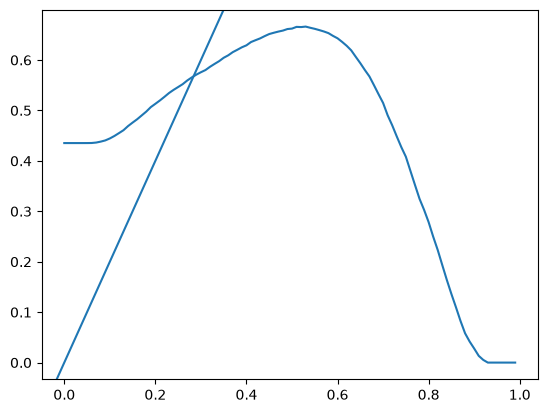

In [4]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

probs = cross_val_predict(model, X_all, y, cv=5, method="predict_proba")[:, 1]

thresholds = np.arange(0.0, 1, 0.01)
f1s = [f1_score(y, probs >= t) for t in thresholds]

best_f1 = max(f1s)
best_threshold = thresholds[f1s.index(best_f1)]

print(f"Best F1 score: {best_f1:.3f}")
print(f"Best threshold: {best_threshold:.3f}")

plt.plot(thresholds, f1s)
plt.axline((0, 0), slope=2)
plt.show()

In [5]:
model.fit(X_all, y)

prediction_probs = pd.Series(
    model.predict_proba(test_all)[:, 1],
    index=df_test.index,
    name="probability"
)

display(prediction_probs.head())

submission = pd.DataFrame({
    "ID": df_test.index,
    "Y": (prediction_probs > .53).astype(int)
})

submission_filepath = "./submissions/rf2.csv"
submission.to_csv(submission_filepath, index=False)

# get percent of positive predictions for .53 as threshold
(prediction_probs > .53).mean()

ID
15001    0.344847
15002    0.299370
15003    0.245628
15004    0.107271
15005    0.144853
Name: probability, dtype: float64

np.float64(0.3012)

## Model assessment

Estimate how many test observations should be classified as positive, then visualize the estimated F-score distribution.

5443

np.float64(0.3300254207742934)

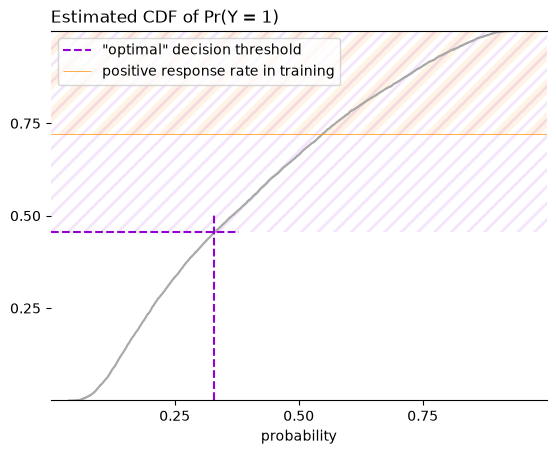

In [6]:
pos_prediction_count, threshold = th.estimate_optimal_threshold(
    prediction_probs
)

display(pos_prediction_count)
display(threshold)

_ = th.plot_probs(
    probs=prediction_probs,
    expt_prob=np.mean(df_train.Y.astype(np.int64)),
    threshold=threshold,
    pos_pred_count=pos_prediction_count,
)

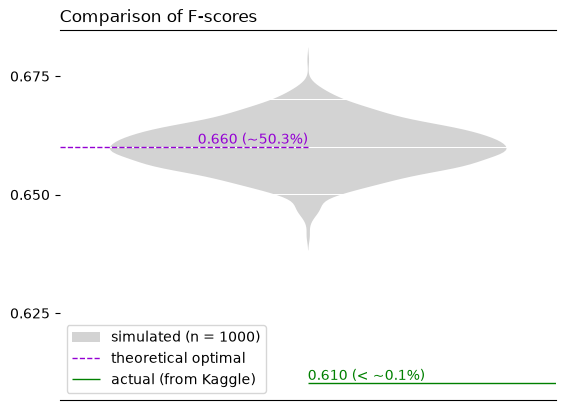

In [7]:
rng = np.random.default_rng(1)

_ = th.plot_f_scores(
    empiricals=th.sample_probable_f_scores(
        rng,
        1000,
        prediction_probs,
        pos_prediction_count
    ),
    calculated=2 * threshold,
    reported=.61021,
)

## Make the submission

Rank test observations by their predicted probability. Assign class `1` to the `pos_prediction_count` highest-probability observations and class `0` to the rest.

In [8]:
predictions = prediction_probs.sort_values(ascending=False)

predictions.iloc[:pos_prediction_count] = 1
predictions.iloc[pos_prediction_count:] = 0

predictions = predictions.astype(np.int8).sort_index()
predictions.name = "Y"

display(predictions.head())
display(predictions.value_counts().sort_index())

ID
15001    1
15002    0
15003    0
15004    0
15005    0
Name: Y, dtype: int8

Y
0    4557
1    5443
Name: count, dtype: int64

In [9]:
import pathlib

submission_filepath = pathlib.Path("./submissions/rf.csv")
submission_filepath.parent.mkdir(parents=True, exist_ok=True)

print(f"Saving submission file to {submission_filepath}")
predictions.to_csv(submission_filepath)

predictions.mean()

Saving submission file to submissions/rf.csv


np.float64(0.5443)